In [1]:
# ============================================
# STEP 1 - IMPORT LIBRARIES
# ============================================

import os
import zipfile
import hashlib
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import (
    GroupShuffleSplit,
    StratifiedGroupKFold,
    cross_validate
)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler
)

from sklearn.impute import SimpleImputer

from sklearn.dummy import DummyClassifier

from sklearn.linear_model import LogisticRegression

from sklearn.tree import DecisionTreeClassifier

from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve
)

warnings.filterwarnings("ignore")

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
# ============================================
# STEP 2 - UPLOAD DATA
# ============================================

from google.colab import files

uploaded = files.upload()

print("\nUploaded files:")
for filename in uploaded.keys():
    print("-", filename)

Saving diabetic_data.csv to diabetic_data (4).csv
Saving IDS_mapping.csv to IDS_mapping (4).csv

Uploaded files:
- diabetic_data (4).csv
- IDS_mapping (4).csv


In [3]:
# ============================================
# STEP 3 - CHECK FILES
# ============================================

print("Files currently in /content:\n")

for filename in os.listdir("/content"):
    print(filename)

Files currently in /content:

.config
diabetic_data.csv
IDS_mapping (1).csv
IDS_mapping (2).csv
data_dictionary.csv
diabetic_data (3).csv
IDS_mapping (3).csv
cross_validation_results.csv
IDS_mapping.csv
final_model_comparison.csv
diabetic_data (1).csv
IDS_mapping (4).csv
diabetic_data (2).csv
diabetic_data (4).csv
sample_data


In [4]:
# ============================================
# STEP 4 - LOAD MAIN DATASET
# ============================================

DATA_PATH = "/content/diabetic_data.csv"

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print()
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Dataset loaded successfully!

Rows: 101766
Columns: 50


In [5]:
# ============================================
# STEP 5 - LOAD IDS MAPPING
# ============================================

MAPPING_PATH = "/content/IDS_mapping.csv"

if os.path.exists(MAPPING_PATH):

    ids_mapping = pd.read_csv(
        MAPPING_PATH,
        header=None
    )

    print("IDS_mapping.csv loaded successfully!")
    print()
    print("Shape:", ids_mapping.shape)

    display(ids_mapping.head(20))

else:

    ids_mapping = None

    print("IDS_mapping.csv was not found.")

IDS_mapping.csv loaded successfully!

Shape: (68, 2)


,0,1
0,admission_type_id,description
1,1,Emergency
2,2,Urgent
3,3,Elective
4,4,Newborn
5,5,Not Available
6,6,NaN
7,7,Trauma Center
8,8,Not Mapped
9,NaN,NaN


In [6]:
# ============================================
# STEP 6 - BASIC DATA INSPECTION
# ============================================

print("Dataset shape:")
print(df.shape)

print("\nFirst 5 rows:")
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
display(df.dtypes)

Dataset shape:
(101766, 50)

First 5 rows:


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),?,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),?,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO



Column names:
['encounter_id', 'patient_nbr', 'race', 'gender', 'age', 'weight', 'admission_type_id', 'discharge_disposition_id', 'admission_source_id', 'time_in_hospital', 'payer_code', 'medical_specialty', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'diag_1', 'diag_2', 'diag_3', 'number_diagnoses', 'max_glu_serum', 'A1Cresult', 'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide', 'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 'examide', 'citoglipton', 'insulin', 'glyburide-metformin', 'glipizide-metformin', 'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'metformin-pioglitazone', 'change', 'diabetesMed', 'readmitted']

Data types:


,0
encounter_id,int64
patient_nbr,int64
race,object
gender,object
age,object
weight,object
admission_type_id,int64
discharge_disposition_id,int64
admission_source_id,int64
time_in_hospital,int64


In [7]:
# ============================================
# STEP 8 - CHECK '?' VALUES
# ============================================

question_mark_counts = (
    df.astype(str) == "?"
).sum()

question_mark_counts = (
    question_mark_counts[
        question_mark_counts > 0
    ]
    .sort_values(ascending=False)
)

print("Columns containing '?' values:")

display(question_mark_counts)

Columns containing '?' values:


,0
weight,98569
medical_specialty,49949
payer_code,40256
race,2273
diag_3,1423
diag_2,358
diag_1,21


In [8]:
# ============================================
# STEP 9 - HANDLE MISSING VALUE SYMBOL
# ============================================

df = df.replace("?", np.nan)

print(" '?' values have been converted to NaN.")

 '?' values have been converted to NaN.


In [9]:
# ============================================
# STEP 9B - DATA DICTIONARY
# ============================================

data_dictionary = pd.DataFrame({
    "Column": df.columns,
    "Data Type": df.dtypes.astype(str).values,
    "Missing Values": df.isna().sum().values,
    "Missing %": (
        df.isna().mean().values * 100
    ).round(2),
    "Unique Values": [
        df[col].nunique(dropna=True)
        for col in df.columns
    ]
})

display(data_dictionary)

,Column,Data Type,Missing Values,Missing %,Unique Values
0,encounter_id,int64,0,0.00,101766
1,patient_nbr,int64,0,0.00,71518
2,race,object,2273,2.23,5
3,gender,object,0,0.00,3
4,age,object,0,0.00,10
5,weight,object,98569,96.86,9
6,admission_type_id,int64,0,0.00,8
7,discharge_disposition_id,int64,0,0.00,26
8,admission_source_id,int64,0,0.00,17
9,time_in_hospital,int64,0,0.00,14


In [10]:
# ============================================
# STEP 10 - MISSING VALUE ANALYSIS
# ============================================

missing_summary = pd.DataFrame({
    "Missing Count": df.isna().sum(),
    "Missing Percentage": (
        df.isna().mean() * 100
    ).round(2)
})

missing_summary = (
    missing_summary[
        missing_summary["Missing Count"] > 0
    ]
    .sort_values(
        "Missing Percentage",
        ascending=False
    )
)

display(missing_summary)

,Missing Count,Missing Percentage
weight,98569,96.86
max_glu_serum,96420,94.75
A1Cresult,84748,83.28
medical_specialty,49949,49.08
payer_code,40256,39.56
race,2273,2.23
diag_3,1423,1.40
diag_2,358,0.35
diag_1,21,0.02


In [11]:
# ============================================
# STEP 11 - DUPLICATE ANALYSIS
# ============================================

duplicate_count = df.duplicated().sum()

print(
    "Number of exact duplicate rows:",
    duplicate_count
)

Number of exact duplicate rows: 0


In [12]:
# ============================================
# STEP 12 - REPEATED PATIENT ANALYSIS
# ============================================

print(
    "Total encounters:",
    len(df)
)

print(
    "Unique patients:",
    df["patient_nbr"].nunique()
)

print(
    "Patients with multiple encounters:",
    (
        df["patient_nbr"].value_counts() > 1
    ).sum()
)

print("\nTop patient encounter counts:")

display(
    df["patient_nbr"]
    .value_counts()
    .head(10)
)

Total encounters: 101766
Unique patients: 71518
Patients with multiple encounters: 16773

Top patient encounter counts:


,count
patient_nbr,
88785891,40
43140906,28
88227540,23
1660293,23
23199021,23
84428613,22
23643405,22
92709351,21
37096866,20


In [13]:
# ============================================
# STEP 12B - REMOVE DEAD / HOSPICE PATIENTS
# ============================================

n_before = len(df)

# Discharge codes 11, 13, 14, 19, 20, 21 indicate
# patient expired or went to hospice → cannot be readmitted
dead_or_hospice_codes = [11, 13, 14, 19, 20, 21]

df = df[
    ~df["discharge_disposition_id"].isin(dead_or_hospice_codes)
].copy()

# Remove the 3 Unknown/Invalid gender rows
df = df[df["gender"] != "Unknown/Invalid"].copy()

n_after = len(df)

print("Rows before:", n_before)
print("Rows after :", n_after)
print("Rows removed:", n_before - n_after)

Rows before: 101766
Rows after : 99340
Rows removed: 2426


In [14]:
# ============================================
# STEP 13 - CREATE TARGET VARIABLE
# ============================================

df["early_readmission"] = (
    df["readmitted"]
    .map({
        "<30": 1,
        "NO": 0,
        ">30": 0
    })
)

print("Target created successfully.")

print("\nTarget value counts:")
display(
    df["early_readmission"]
    .value_counts()
)

print("\nTarget percentages:")
display(
    (
        df["early_readmission"]
        .value_counts(normalize=True)
        * 100
    ).round(2)
)

Target created successfully.

Target value counts:


,count
early_readmission,
0,88026
1,11314



Target percentages:


,proportion
early_readmission,
0,88.61
1,11.39


In [15]:
# ============================================
# STEP 13B - FEATURE ENGINEERING
# ============================================

# 1. Total prior visits (inpatient + emergency + outpatient)
df["total_prior_visits"] = (
    df["number_inpatient"]
    + df["number_emergency"]
    + df["number_outpatient"]
)

# 2. Any prior inpatient visit (binary flag)
df["has_prior_inpatient"] = (
    df["number_inpatient"] > 0
).astype(int)

# 3. Diagnosis grouping function (ICD-9 chapters)
def map_diagnosis(code):
    if pd.isna(code):
        return "Missing"
    code = str(code)

    # Handle V and E codes
    if code.startswith("V"):
        return "Supplementary"
    if code.startswith("E"):
        return "External"

    try:
        num = float(code)
    except ValueError:
        return "Other"

    if 1 <= num <= 139:   return "Infectious"
    if 140 <= num <= 239: return "Neoplasms"
    if 240 <= num <= 279: return "Endocrine"
    if 280 <= num <= 289: return "Blood"
    if 290 <= num <= 319: return "Mental"
    if 320 <= num <= 389: return "Nervous"
    if 390 <= num <= 459: return "Circulatory"
    if 460 <= num <= 519: return "Respiratory"
    if 520 <= num <= 579: return "Digestive"
    if 580 <= num <= 629: return "Genitourinary"
    if 630 <= num <= 679: return "Pregnancy"
    if 680 <= num <= 709: return "Skin"
    if 710 <= num <= 739: return "Musculoskeletal"
    if 740 <= num <= 759: return "Congenital"
    if 760 <= num <= 779: return "Perinatal"
    if 780 <= num <= 799: return "Symptoms"
    if 800 <= num <= 999: return "Injury"
    return "Other"

for col in ["diag_1", "diag_2", "diag_3"]:
    df[col + "_group"] = df[col].apply(map_diagnosis)

# 4. Drop raw diagnosis columns (replaced by groups)
df = df.drop(columns=["diag_1", "diag_2", "diag_3"])

# 5. Age to numeric midpoint
age_map = {
    "[0-10)": 5, "[10-20)": 15, "[20-30)": 25, "[30-40)": 35,
    "[40-50)": 45, "[50-60)": 55, "[60-70)": 65, "[70-80)": 75,
    "[80-90)": 85, "[90-100)": 95
}
df["age_numeric"] = df["age"].map(age_map)

print("Feature engineering complete.")
print("New columns added:",
      ["total_prior_visits", "has_prior_inpatient",
       "diag_1_group", "diag_2_group", "diag_3_group", "age_numeric"])
print("\nNew shape:", df.shape)

Feature engineering complete.
New columns added: ['total_prior_visits', 'has_prior_inpatient', 'diag_1_group', 'diag_2_group', 'diag_3_group', 'age_numeric']

New shape: (99340, 54)


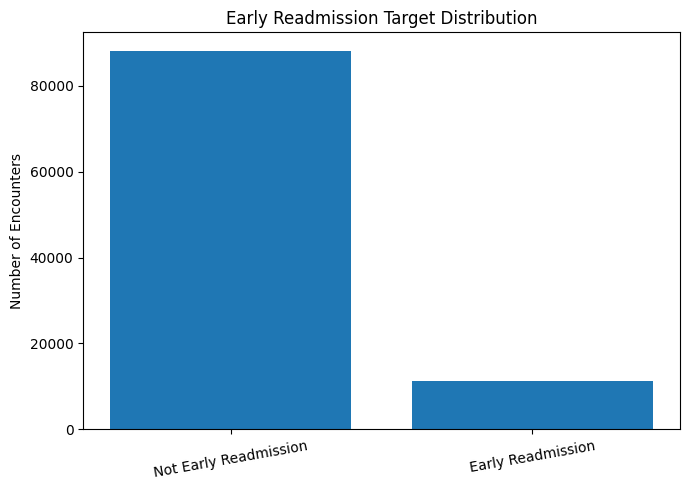

In [16]:
# ============================================
# STEP 14 - TARGET DISTRIBUTION
# ============================================

target_counts = df[
    "early_readmission"
].value_counts().sort_index()

plt.figure(figsize=(7, 5))

plt.bar(
    ["Not Early Readmission", "Early Readmission"],
    target_counts.values
)

plt.title(
    "Early Readmission Target Distribution"
)

plt.ylabel("Number of Encounters")

plt.xticks(rotation=10)

plt.tight_layout()

plt.show()

# Target Definition

The original `readmitted` variable contains three outcomes:

- `NO` — patient was not readmitted
- `>30` — patient was readmitted after 30 days
- `<30` — patient was readmitted within 30 days

For this project, the target was converted into a binary classification problem:

- `<30` → `1` = Early Readmission
- `NO` → `0` = Not Early Readmission
- `>30` → `0` = Not Early Readmission

The objective is to classify whether a hospital encounter belongs to the early-readmission category.

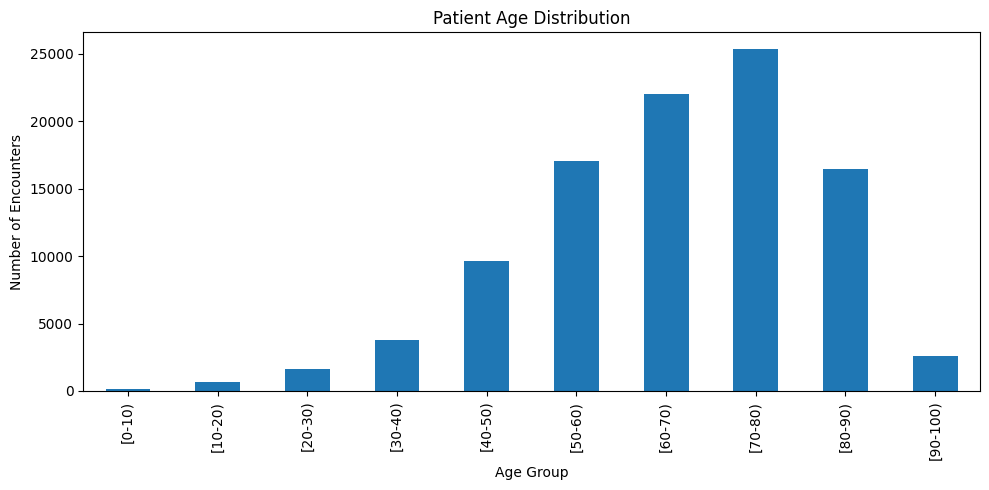

In [17]:
# ============================================
# STEP 16 - AGE DISTRIBUTION
# ============================================

plt.figure(figsize=(10, 5))

df["age"].value_counts().sort_index().plot(
    kind="bar"
)

plt.title("Patient Age Distribution")
plt.xlabel("Age Group")
plt.ylabel("Number of Encounters")

plt.tight_layout()
plt.show()

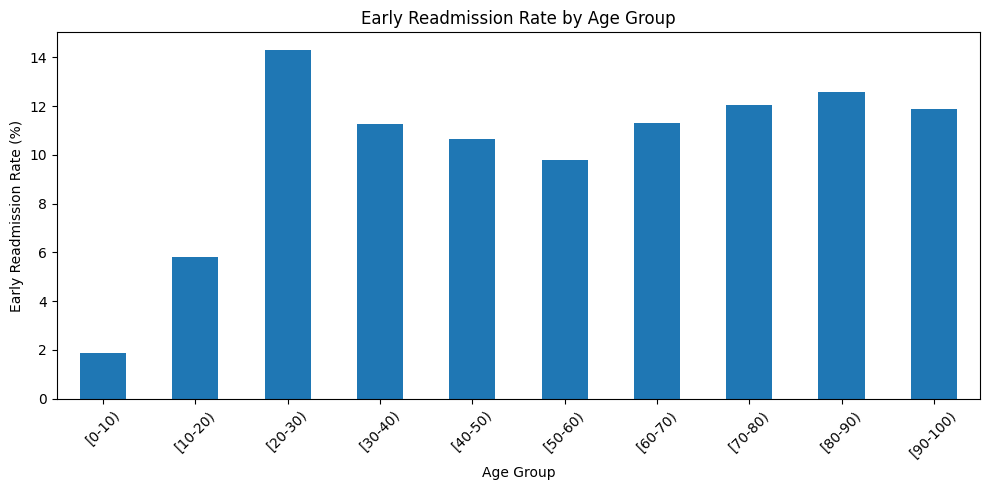

In [18]:
# ============================================
# STEP 17 - EARLY READMISSION BY AGE
# ============================================

age_readmission = (
    df.groupby("age")[
        "early_readmission"
    ]
    .mean()
    .sort_index()
    * 100
)

plt.figure(figsize=(10, 5))

age_readmission.plot(
    kind="bar"
)

plt.title(
    "Early Readmission Rate by Age Group"
)

plt.xlabel("Age Group")
plt.ylabel("Early Readmission Rate (%)")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

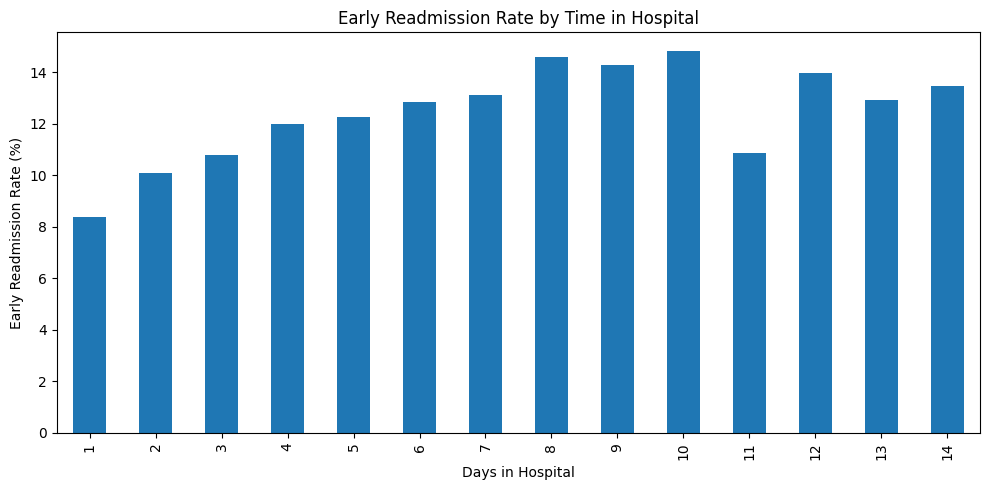

In [19]:
# ============================================
# STEP 18 - TIME IN HOSPITAL
# ============================================

plt.figure(figsize=(10, 5))

df.groupby(
    "time_in_hospital"
)["early_readmission"].mean().mul(100).plot(
    kind="bar"
)

plt.title(
    "Early Readmission Rate by Time in Hospital"
)

plt.xlabel("Days in Hospital")
plt.ylabel("Early Readmission Rate (%)")

plt.tight_layout()
plt.show()

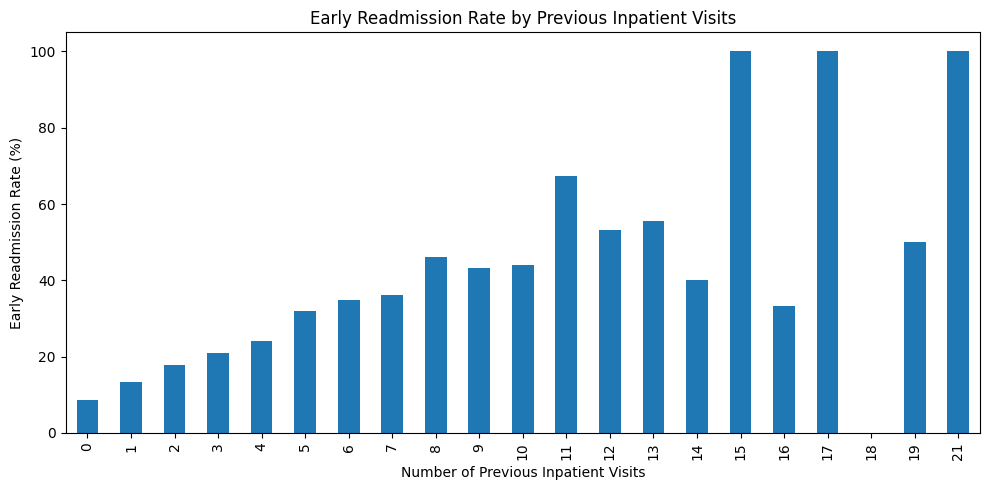

In [20]:
# ============================================
# STEP 19 - PREVIOUS INPATIENT VISITS
# ============================================

plt.figure(figsize=(10, 5))

df.groupby(
    "number_inpatient"
)["early_readmission"].mean().mul(100).plot(
    kind="bar"
)

plt.title(
    "Early Readmission Rate by Previous Inpatient Visits"
)

plt.xlabel("Number of Previous Inpatient Visits")
plt.ylabel("Early Readmission Rate (%)")

plt.tight_layout()
plt.show()

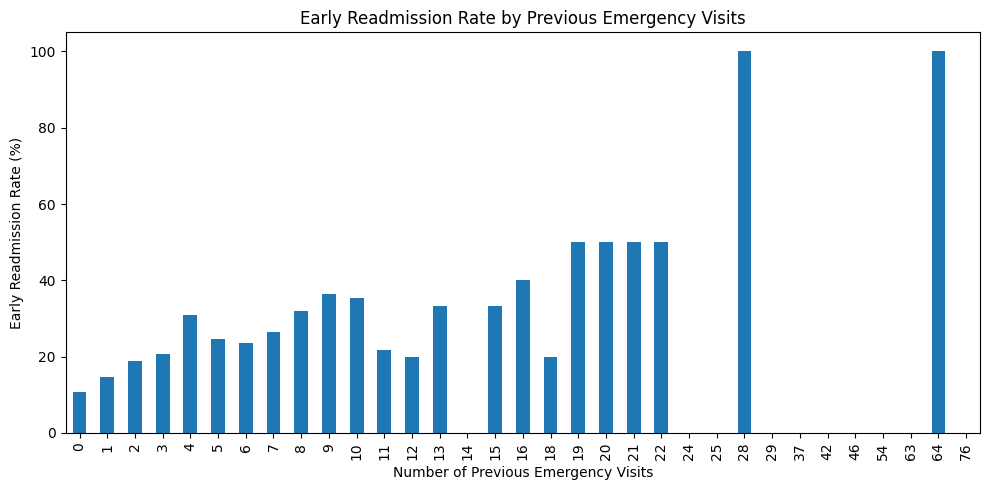

In [21]:
# ============================================
# STEP 20 - PREVIOUS EMERGENCY VISITS
# ============================================

plt.figure(figsize=(10, 5))

df.groupby(
    "number_emergency"
)["early_readmission"].mean().mul(100).plot(
    kind="bar"
)

plt.title(
    "Early Readmission Rate by Previous Emergency Visits"
)

plt.xlabel("Number of Previous Emergency Visits")
plt.ylabel("Early Readmission Rate (%)")

plt.tight_layout()
plt.show()

,count,Early Readmission %
gender,,
Female,53454,11.46
Male,45886,11.30


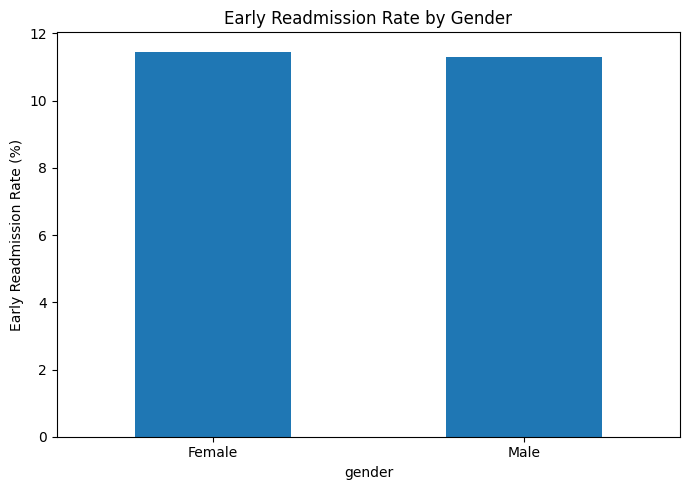

In [22]:
# ============================================
# STEP 21 - GENDER ANALYSIS
# ============================================

gender_summary = (
    df.groupby("gender")[
        "early_readmission"
    ]
    .agg(
        ["count", "mean"]
    )
)

gender_summary["Early Readmission %"] = (
    gender_summary["mean"] * 100
).round(2)

gender_summary = gender_summary.drop(
    columns=["mean"]
)

display(gender_summary)

plt.figure(figsize=(7, 5))

gender_summary[
    "Early Readmission %"
].plot(kind="bar")

plt.title(
    "Early Readmission Rate by Gender"
)

plt.ylabel("Early Readmission Rate (%)")

plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

# EDA Insight Log

The exploratory analysis was used to understand the distribution of the target and identify potentially useful relationships between encounter characteristics and early readmission.

| Observation | Decision |
|---|---|
| 11.39% of encounters are early readmissions | Use class weights; report PR-AUC, recall and F1 |
| Early-readmission rate rises with prior inpatient visits: 8.6% (0 visits) → 31.4% (4+) | Created `total_prior_visits` and `has_prior_inpatient` |
| Rises with prior emergency visits: 10.7% (0) → 25.3% (3+) | Included in `total_prior_visits` |
| Rises with length of stay: 8.4% (1 day) → about 14–15% (8–10 days) | Kept `time_in_hospital` |
| Gender shows almost no difference (11.46% vs 11.30%) | Weak predictor; kept but not expected to matter |

# Leakage and Feature Review

The dataset contains identifiers and outcome-related variables.

The following variables will not be used as predictive features:

| Variable | Decision | Reason |
|---|---|---|
| `encounter_id` | Exclude | Identifier for a hospital encounter |
| `patient_nbr` | Exclude from predictors | Patient identifier; used only for grouping |
| `readmitted` | Exclude | Original outcome variable used to construct the target |
| `early_readmission` | Exclude | Target variable |
| Discharge codes 11, 13, 14, 19, 20, 21 (died / hospice) | Rows removed (2,423) | These patients cannot be readmitted |
| `weight` | Dropped | 96.86% missing |
| Admission / discharge / source IDs | Treated as categorical | They are codes, not quantities |
| `diag_1/2/3` | Grouped into ICD-9 chapters | Raw codes are too sparse |

`patient_nbr` was retained separately as a grouping variable so that encounters from the same patient were not split between the training and testing datasets (verified with a patient-overlap check after the split).

All retained predictors (demographics, admission/discharge coding, prior utilisation counts, diagnosis groups, lab/procedure counts and medication information) are recorded during the hospital encounter and are therefore available at the point of discharge, which is the intended prediction point.

In [23]:
# ============================================
# STEP 23B - SEMANTIC MISSING VALUE HANDLING
# ============================================

# 1. Drop weight (96.86% missing - not recoverable)
df = df.drop(columns=["weight"])

# 2. Missing = "Unknown" for these columns
for c in ["race", "payer_code", "medical_specialty"]:
    df[c] = df[c].fillna("Unknown")

# 3. Missing = "Not tested" for lab tests
#    (missing means the test was NOT ordered)
for c in ["A1Cresult", "max_glu_serum"]:
    df[c] = df[c].fillna("Not tested")

# 4. Convert numeric ID codes to strings
#    (they are identifiers, not quantities)
for c in ["admission_type_id",
          "discharge_disposition_id",
          "admission_source_id"]:
    df[c] = df[c].astype(str)

print("After semantic missing value handling:")
print("Shape:", df.shape)
print("\nRemaining missing values:")
print(df.isna().sum()[df.isna().sum() > 0])

After semantic missing value handling:
Shape: (99340, 53)

Remaining missing values:
Series([], dtype: int64)


In [24]:
# ============================================
# STEP 24 - PREPARE X, y AND GROUPS
# ============================================

target = "early_readmission"

columns_to_remove = [
    "encounter_id",
    "patient_nbr",
    "readmitted",
    "early_readmission"
]

# Predictor variables
X = df.drop(
    columns=columns_to_remove
).copy()

# Target
y = df[target].copy()

# Patient grouping variable
groups = df["patient_nbr"].copy()

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Number of unique patients:", groups.nunique())

print("\nTarget distribution:")
display(y.value_counts())

X shape: (99340, 49)
y shape: (99340,)
Number of unique patients: 69987

Target distribution:


,count
early_readmission,
0,88026
1,11314


In [25]:
# ============================================
# STEP 25 - PATIENT-LEVEL TRAIN/TEST SPLIT
# ============================================

gss = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    gss.split(
        X,
        y,
        groups=groups
    )
)

X_train = X.iloc[train_idx].copy()
X_test = X.iloc[test_idx].copy()

y_train = y.iloc[train_idx].copy()
y_test = y.iloc[test_idx].copy()

groups_train = groups.iloc[train_idx].copy()
groups_test = groups.iloc[test_idx].copy()

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

print("\nTraining patients:", groups_train.nunique())
print("Testing patients:", groups_test.nunique())

# Check patient overlap
patient_overlap = set(
    groups_train.unique()
).intersection(
    set(groups_test.unique())
)

print(
    "\nPatients appearing in both train and test:",
    len(patient_overlap)
)

print("\nTraining target distribution:")
display(
    y_train.value_counts(normalize=True)
)

print("\nTesting target distribution:")
display(
    y_test.value_counts(normalize=True)
)

Training rows: 79567
Testing rows: 19773

Training patients: 55989
Testing patients: 13998

Patients appearing in both train and test: 0

Training target distribution:


,proportion
early_readmission,
0,0.886008
1,0.113992



Testing target distribution:


,proportion
early_readmission,
0,0.886512
1,0.113488


In [26]:
# ============================================
# STEP 26 - PREPROCESSING
# ============================================

numeric_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical features:", len(numeric_features))
print("Categorical features:", len(categorical_features))

# Numerical pipeline: scale only (missing values were handled semantically)
numeric_transformer = Pipeline(
    steps=[
        ("scaler", StandardScaler())
    ]
)

# Categorical pipeline: one-hot encode with min_frequency threshold
categorical_transformer = Pipeline(
    steps=[
        ("onehot", OneHotEncoder(
            handle_unknown="ignore",
            min_frequency=0.01
        ))
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("\nPreprocessing pipeline created successfully.")

Numerical features: 11
Categorical features: 38

Preprocessing pipeline created successfully.


# Preprocessing and Feature Decision Log

| Issue | Decision | Reason |
|---|---|---|
| `weight` column (96.86% missing) | Dropped | Not recoverable; too sparse to impute meaningfully |
| `?` placeholder values | Replaced with `NaN` | `?` is the dataset's marker for missing, not a real category |
| Missing `race`, `payer_code`, `medical_specialty` | Filled with `"Unknown"` | Missingness is itself informative (e.g. not recorded), so a separate category is preferable to mode imputation |
| Missing `A1Cresult`, `max_glu_serum` | Filled with `"Not tested"` | Missing indicates the test was not ordered, which is a meaningful clinical state |
| Numeric ID codes (`admission_type_id`, `discharge_disposition_id`, `admission_source_id`) | Converted to string and treated as categorical | These are identifiers, not quantities — numeric magnitude has no meaning |
| Categorical features | One-hot encoding with `min_frequency=0.01` | Represents nominal categories without imposing order; rare levels are grouped to control dimensionality |
| Numerical features | Standard scaling | Useful for scale-sensitive models such as Logistic Regression |
| Patient ID (`patient_nbr`) | Excluded from predictors; kept as grouping variable | Identifier rather than a meaningful predictive variable |
| Encounter ID | Excluded | Identifier |
| Original `readmitted` outcome | Excluded | Used to construct the binary target |
| Class imbalance | Class weighting (`balanced` / `balanced_subsample`) | Gives greater importance to the minority class without creating synthetic observations |

In [27]:
# ============================================
# STEP 28 - BASELINE MODEL
# ============================================

baseline_model = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "model",
            DummyClassifier(
                strategy="most_frequent"
            )
        )
    ]
)

baseline_model.fit(
    X_train,
    y_train
)

baseline_pred = baseline_model.predict(
    X_test
)

print(
    classification_report(
        y_test,
        baseline_pred,
        target_names=[
            "Not Early Readmission",
            "Early Readmission"
        ],
        zero_division=0
    )
)

                       precision    recall  f1-score   support

Not Early Readmission       0.89      1.00      0.94     17529
    Early Readmission       0.00      0.00      0.00      2244

             accuracy                           0.89     19773
            macro avg       0.44      0.50      0.47     19773
         weighted avg       0.79      0.89      0.83     19773



In [28]:
# ============================================
# STEP 29 - LOGISTIC REGRESSION
# ============================================

logistic_model = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "model",
            LogisticRegression(
                max_iter=1000,
                class_weight="balanced",
                random_state=42
            )
        )
    ]
)

logistic_model.fit(
    X_train,
    y_train
)

logistic_pred = logistic_model.predict(
    X_test
)

logistic_prob = logistic_model.predict_proba(
    X_test
)[:, 1]

print(
    classification_report(
        y_test,
        logistic_pred,
        target_names=[
            "Not Early Readmission",
            "Early Readmission"
        ],
        zero_division=0
    )
)

                       precision    recall  f1-score   support

Not Early Readmission       0.92      0.67      0.78     17529
    Early Readmission       0.18      0.57      0.28      2244

             accuracy                           0.66     19773
            macro avg       0.55      0.62      0.53     19773
         weighted avg       0.84      0.66      0.72     19773



In [29]:
# ============================================
# STEP 30 - DECISION TREE
# ============================================

tree_model = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "model",
            DecisionTreeClassifier(
                max_depth=10,
                min_samples_leaf=20,
                class_weight="balanced",
                random_state=42
            )
        )
    ]
)

tree_model.fit(
    X_train,
    y_train
)

tree_pred = tree_model.predict(
    X_test
)

tree_prob = tree_model.predict_proba(
    X_test
)[:, 1]

print(
    classification_report(
        y_test,
        tree_pred,
        target_names=[
            "Not Early Readmission",
            "Early Readmission"
        ],
        zero_division=0
    )
)

                       precision    recall  f1-score   support

Not Early Readmission       0.92      0.62      0.74     17529
    Early Readmission       0.16      0.59      0.26      2244

             accuracy                           0.61     19773
            macro avg       0.54      0.60      0.50     19773
         weighted avg       0.83      0.61      0.68     19773



In [30]:
# ============================================
# STEP 31 - RANDOM FOREST
# ============================================

rf_model = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "model",
            RandomForestClassifier(
                n_estimators=300,
                max_depth=20,
                min_samples_leaf=5,
                class_weight="balanced_subsample",
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

rf_model.fit(
    X_train,
    y_train
)

rf_pred = rf_model.predict(
    X_test
)

rf_prob = rf_model.predict_proba(
    X_test
)[:, 1]

print(
    classification_report(
        y_test,
        rf_pred,
        target_names=[
            "Not Early Readmission",
            "Early Readmission"
        ],
        zero_division=0
    )
)

                       precision    recall  f1-score   support

Not Early Readmission       0.91      0.88      0.89     17529
    Early Readmission       0.24      0.31      0.27      2244

             accuracy                           0.81     19773
            macro avg       0.58      0.59      0.58     19773
         weighted avg       0.83      0.81      0.82     19773



In [31]:
# ============================================
# STEP 32 - EXTRA TREES
# ============================================

extra_trees_model = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "model",
            ExtraTreesClassifier(
                n_estimators=300,
                max_depth=20,
                min_samples_leaf=5,
                class_weight="balanced",
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

extra_trees_model.fit(
    X_train,
    y_train
)

extra_trees_pred = (
    extra_trees_model.predict(X_test)
)

extra_trees_prob = (
    extra_trees_model
    .predict_proba(X_test)[:, 1]
)

print(
    classification_report(
        y_test,
        extra_trees_pred,
        target_names=[
            "Not Early Readmission",
            "Early Readmission"
        ],
        zero_division=0
    )
)

                       precision    recall  f1-score   support

Not Early Readmission       0.92      0.77      0.84     17529
    Early Readmission       0.21      0.46      0.28      2244

             accuracy                           0.74     19773
            macro avg       0.56      0.62      0.56     19773
         weighted avg       0.84      0.74      0.78     19773



In [32]:
# ============================================
# STEP 33 - MODEL COMPARISON
# ============================================

from sklearn.metrics import average_precision_score

def evaluate_model(
    model_name,
    y_true,
    predictions,
    probabilities=None
):

    result = {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, predictions),
        "Precision": precision_score(y_true, predictions, zero_division=0),
        "Recall": recall_score(y_true, predictions, zero_division=0),
        "F1 Score": f1_score(y_true, predictions, zero_division=0)
    }

    if probabilities is not None:
        result["ROC-AUC"] = roc_auc_score(y_true, probabilities)
        result["PR-AUC"] = average_precision_score(y_true, probabilities)
    else:
        result["ROC-AUC"] = np.nan
        result["PR-AUC"] = np.nan

    return result


results = []

results.append(
    evaluate_model(
        "Dummy Baseline",
        y_test,
        baseline_pred
    )
)

results.append(
    evaluate_model(
        "Logistic Regression",
        y_test,
        logistic_pred,
        logistic_prob
    )
)

results.append(
    evaluate_model(
        "Decision Tree",
        y_test,
        tree_pred,
        tree_prob
    )
)

results.append(
    evaluate_model(
        "Random Forest",
        y_test,
        rf_pred,
        rf_prob
    )
)

results.append(
    evaluate_model(
        "Extra Trees",
        y_test,
        extra_trees_pred,
        extra_trees_prob
    )
)

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="F1 Score",
    ascending=False
).reset_index(drop=True)

display(
    results_df.round(4)
)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
0,Extra Trees,0.7382,0.2061,0.4581,0.2843,0.6783,0.2300
1,Logistic Regression,0.6606,0.1821,0.5700,0.2760,0.6688,0.2208
2,Random Forest,0.8115,0.2425,0.3115,0.2727,0.6770,0.2292
3,Decision Tree,0.6126,0.1633,0.5856,0.2554,0.6398,0.2062
4,Dummy Baseline,0.8865,0.0000,0.0000,0.0000,NaN,NaN


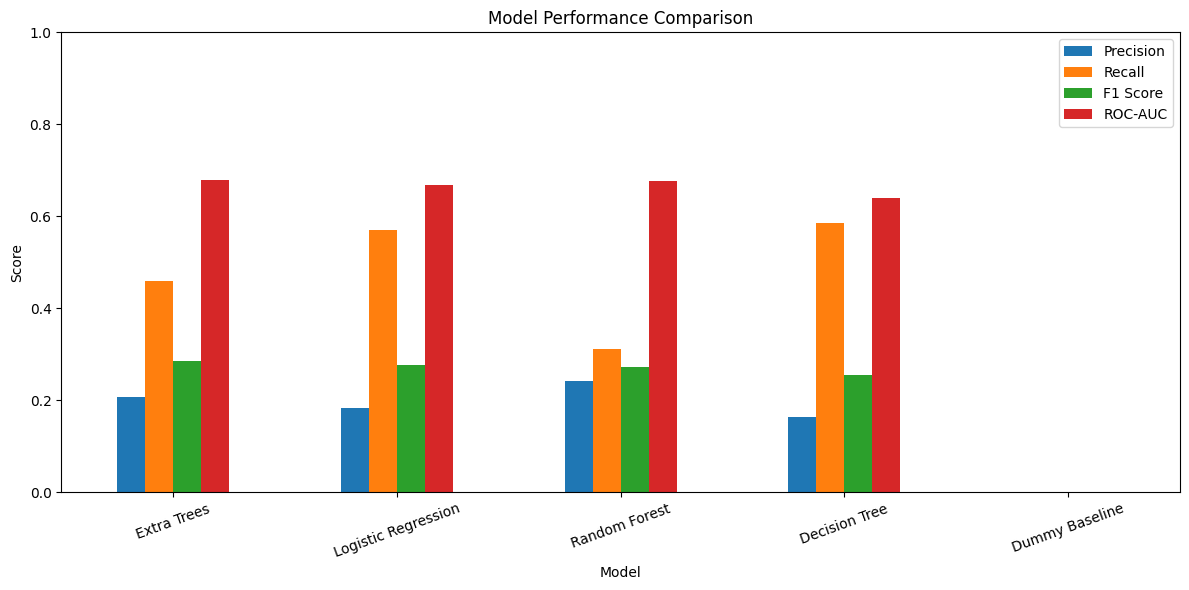

In [33]:
# ============================================
# STEP 34 - MODEL COMPARISON GRAPH
# ============================================

plot_df = results_df.set_index(
    "Model"
)[
    [
        "Precision",
        "Recall",
        "F1 Score",
        "ROC-AUC"
    ]
]

plot_df.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title(
    "Model Performance Comparison"
)

plt.ylabel("Score")

plt.ylim(0, 1)

plt.xticks(rotation=20)

plt.tight_layout()

plt.show()

In [34]:
# ============================================
# STEP 35 - GROUP-AWARE CROSS-VALIDATION
# ============================================

from sklearn.base import clone

cv = StratifiedGroupKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

# Build FRESH unfitted pipelines so CV is comparable across models
models_for_cv = {
    "Logistic Regression": Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("model", LogisticRegression(
            max_iter=1000,
            class_weight="balanced",
            random_state=42
        ))
    ]),
    "Decision Tree": Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("model", DecisionTreeClassifier(
            max_depth=10,
            min_samples_leaf=20,
            class_weight="balanced",
            random_state=42
        ))
    ]),
    "Random Forest": Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("model", RandomForestClassifier(
            n_estimators=300,
            max_depth=20,
            min_samples_leaf=5,
            class_weight="balanced_subsample",
            random_state=42,
            n_jobs=-1
        ))
    ]),
    "Extra Trees": Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("model", ExtraTreesClassifier(
            n_estimators=300,
            max_depth=20,
            min_samples_leaf=5,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        ))
    ]),
}

cv_results = []

for model_name, model in models_for_cv.items():

    print(f"Running CV for: {model_name} ...")

    scores = cross_validate(
        model,
        X_train,
        y_train,
        groups=groups_train.values,
        cv=cv,
        scoring=[
            "accuracy",
            "precision",
            "recall",
            "f1",
            "roc_auc",
            "average_precision"
        ],
        n_jobs=-1,
        error_score="raise"
    )

    cv_results.append({
        "Model":         model_name,
        "CV Accuracy":   scores["test_accuracy"].mean(),
        "CV Precision":  scores["test_precision"].mean(),
        "CV Recall":     scores["test_recall"].mean(),
        "CV F1":         scores["test_f1"].mean(),
        "CV ROC-AUC":    scores["test_roc_auc"].mean(),
        "CV PR-AUC":     scores["test_average_precision"].mean()
    })

    print(f"   done. CV ROC-AUC = {scores['test_roc_auc'].mean():.4f}")

cv_results_df = pd.DataFrame(cv_results).sort_values(
    by="CV ROC-AUC",
    ascending=False
).reset_index(drop=True)

print("\nAll CV results:")
display(cv_results_df.round(4))

Running CV for: Logistic Regression ...
   done. CV ROC-AUC = 0.6597
Running CV for: Decision Tree ...
   done. CV ROC-AUC = 0.6322
Running CV for: Random Forest ...
   done. CV ROC-AUC = 0.6661
Running CV for: Extra Trees ...
   done. CV ROC-AUC = 0.6630

All CV results:


,Model,CV Accuracy,CV Precision,CV Recall,CV F1,CV ROC-AUC,CV PR-AUC
0,Random Forest,0.8193,0.2364,0.2618,0.2482,0.6661,0.2112
1,Extra Trees,0.7463,0.2040,0.4223,0.2751,0.6630,0.2141
2,Logistic Regression,0.6563,0.1783,0.5584,0.2703,0.6597,0.2081
3,Decision Tree,0.6175,0.1649,0.5725,0.2550,0.6322,0.1922



Logistic Regression
[[11784  5745]
 [  965  1279]]


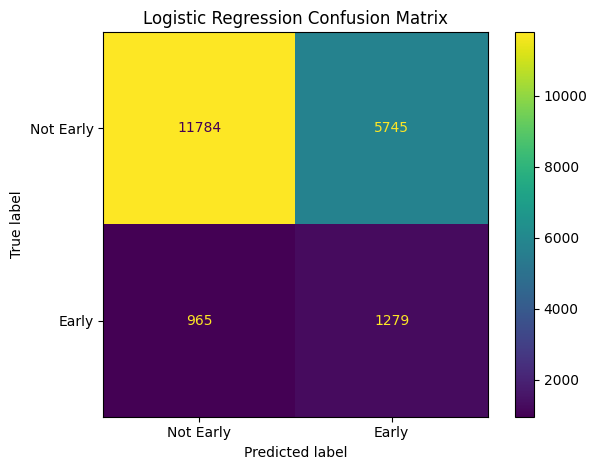


Decision Tree
[[10798  6731]
 [  930  1314]]


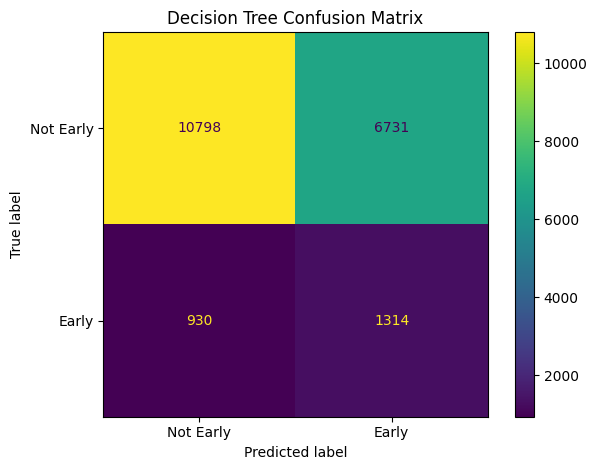


Random Forest
[[15346  2183]
 [ 1545   699]]


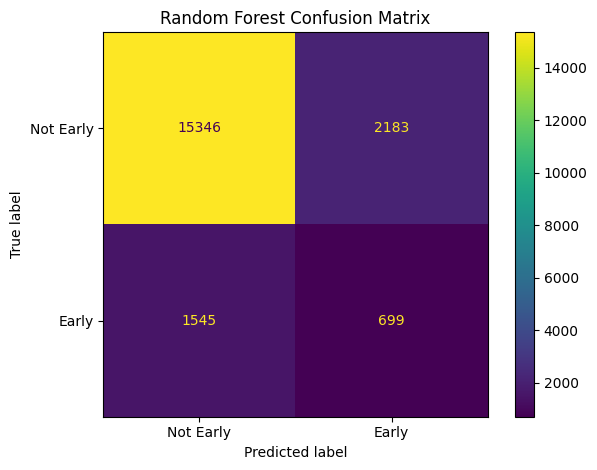


Extra Trees
[[13569  3960]
 [ 1216  1028]]


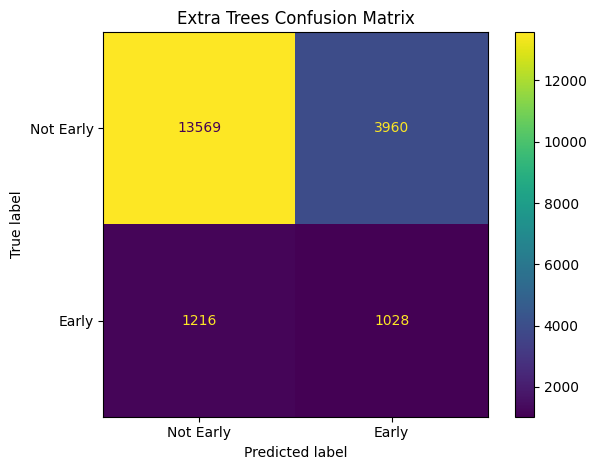

In [35]:
# ============================================
# STEP 36 - CONFUSION MATRICES
# ============================================

model_predictions = {
    "Logistic Regression": logistic_pred,
    "Decision Tree": tree_pred,
    "Random Forest": rf_pred,
    "Extra Trees": extra_trees_pred
}

for model_name, predictions in model_predictions.items():

    cm = confusion_matrix(
        y_test,
        predictions
    )

    print("\n", "=" * 50)
    print(model_name)
    print("=" * 50)

    print(cm)

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=[
            "Not Early",
            "Early"
        ]
    )

    disp.plot()

    plt.title(
        f"{model_name} Confusion Matrix"
    )

    plt.tight_layout()
    plt.show()

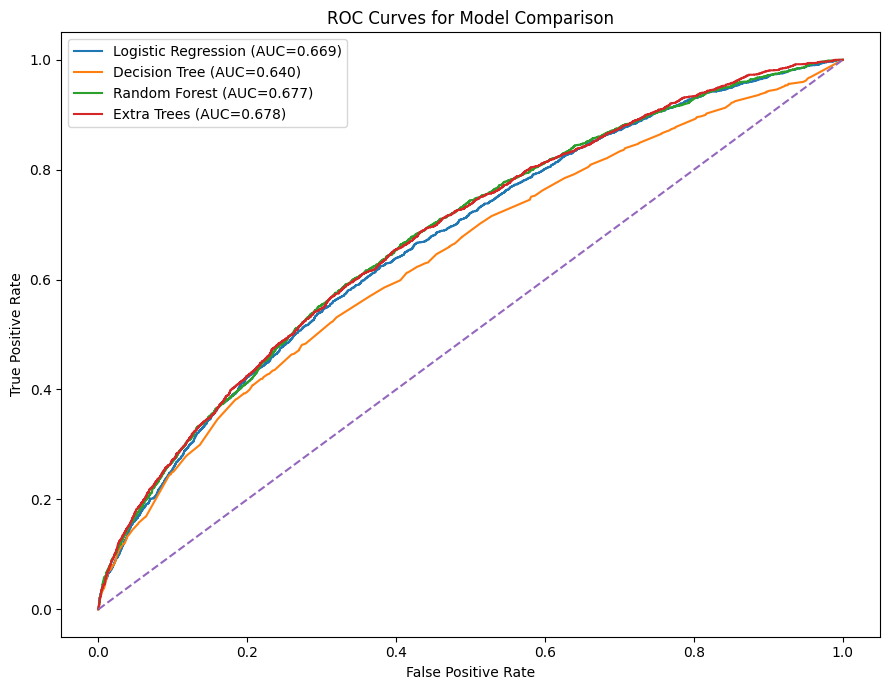

In [36]:
# ============================================
# STEP 37 - ROC CURVES
# ============================================

probability_models = {
    "Logistic Regression": logistic_prob,
    "Decision Tree": tree_prob,
    "Random Forest": rf_prob,
    "Extra Trees": extra_trees_prob
}

plt.figure(figsize=(9, 7))

for model_name, probabilities in probability_models.items():

    fpr, tpr, _ = roc_curve(
        y_test,
        probabilities
    )

    auc_score = roc_auc_score(
        y_test,
        probabilities
    )

    plt.plot(
        fpr,
        tpr,
        label=f"{model_name} (AUC={auc_score:.3f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title(
    "ROC Curves for Model Comparison"
)

plt.legend()

plt.tight_layout()

plt.show()

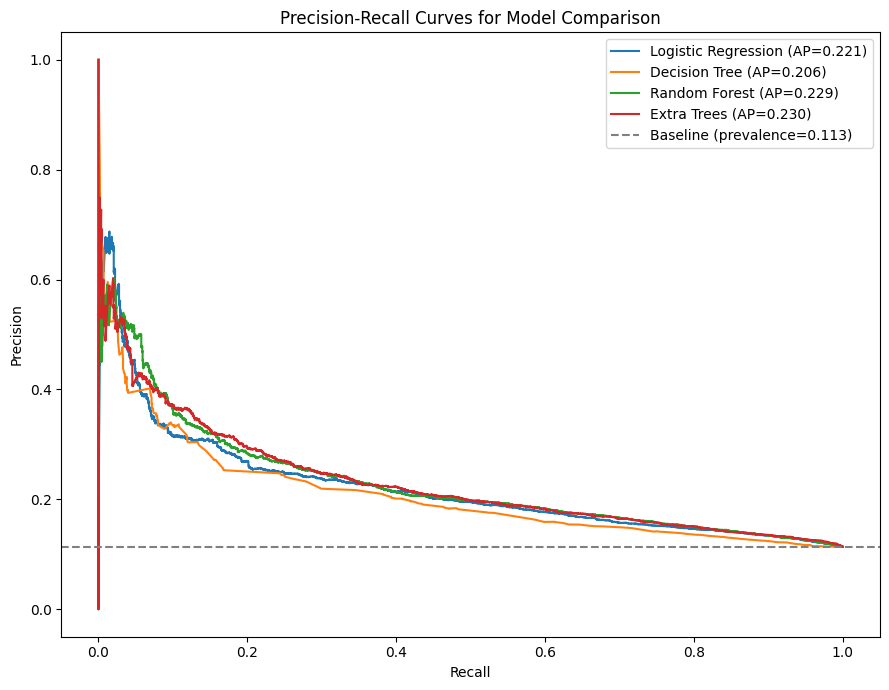

In [37]:
# ============================================
# STEP 37B - PRECISION-RECALL CURVES
# ============================================

from sklearn.metrics import (
    precision_recall_curve,
    average_precision_score
)

plt.figure(figsize=(9, 7))

for model_name, probabilities in probability_models.items():

    precision, recall, _ = precision_recall_curve(
        y_test,
        probabilities
    )

    ap_score = average_precision_score(
        y_test,
        probabilities
    )

    plt.plot(
        recall,
        precision,
        label=f"{model_name} (AP={ap_score:.3f})"
    )

# Baseline: prevalence of positive class
baseline = y_test.mean()

plt.axhline(
    y=baseline,
    linestyle="--",
    color="gray",
    label=f"Baseline (prevalence={baseline:.3f})"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curves for Model Comparison")
plt.legend()
plt.tight_layout()
plt.show()

In [38]:
# ============================================
# STEP 37C - THRESHOLD SELECTION ON TRAINING OOF
# ============================================

from sklearn.model_selection import cross_val_predict

# Out-of-fold predictions on TRAINING data only
oof_probs = cross_val_predict(
    extra_trees_model,
    X_train,
    y_train,
    groups=groups_train,
    cv=cv,
    method="predict_proba",
    n_jobs=1
)[:, 1]

thresholds = np.arange(0.10, 0.71, 0.05)

oof_f1_scores = [
    f1_score(y_train, (oof_probs >= t).astype(int), zero_division=0)
    for t in thresholds
]

best_idx = int(np.argmax(oof_f1_scores))
chosen_threshold = thresholds[best_idx]

print("Threshold chosen on training OOF:", round(chosen_threshold, 2))
print("OOF F1 at that threshold:", round(oof_f1_scores[best_idx], 4))

oof_table = pd.DataFrame({
    "Threshold": thresholds,
    "OOF F1":    np.round(oof_f1_scores, 4),
    "OOF Precision": [
        precision_score(y_train, (oof_probs >= t).astype(int), zero_division=0)
        for t in thresholds
    ],
    "OOF Recall": [
        recall_score(y_train, (oof_probs >= t).astype(int), zero_division=0)
        for t in thresholds
    ]
})
display(oof_table)

Threshold chosen on training OOF: 0.5
OOF F1 at that threshold: 0.2751


,Threshold,OOF F1,OOF Precision,OOF Recall
0,0.10,0.2048,0.114063,0.999890
1,0.15,0.2052,0.114356,0.999559
2,0.20,0.2066,0.115267,0.997133
3,0.25,0.2121,0.118878,0.980816
4,0.30,0.2242,0.127410,0.933958
5,0.35,0.2422,0.141480,0.841345
6,0.40,0.2594,0.158653,0.710474
7,0.45,0.2723,0.178891,0.569570
8,0.50,0.2751,0.203994,0.422381
9,0.55,0.2429,0.236053,0.250055


In [39]:
# ============================================
# STEP 37D - TEST SET SENSITIVITY ANALYSIS
# ============================================
# NOTE: This table is shown for diagnostic purposes only.
# The final threshold was chosen on training OOF predictions (STEP 37C).
# Tuning on the test set would constitute data leakage.

# Focus on the best performing model (Extra Trees)
best_prob = extra_trees_prob

thresholds = np.arange(0.10, 0.71, 0.05)
threshold_results = []

for t in thresholds:
    preds = (best_prob >= t).astype(int)
    threshold_results.append({
        "Threshold": round(t, 2),
        "Precision": precision_score(y_test, preds, zero_division=0),
        "Recall":    recall_score(y_test, preds, zero_division=0),
        "F1":        f1_score(y_test, preds, zero_division=0)
    })

threshold_df = pd.DataFrame(threshold_results)
display(threshold_df.round(4))

,Threshold,Precision,Recall,F1
0,0.10,0.1136,1.0000,0.2040
1,0.15,0.1138,1.0000,0.2044
2,0.20,0.1147,0.9996,0.2058
3,0.25,0.1184,0.9920,0.2116
4,0.30,0.1265,0.9550,0.2235
5,0.35,0.1391,0.8676,0.2397
6,0.40,0.1577,0.7482,0.2605
7,0.45,0.1793,0.6123,0.2774
8,0.50,0.2061,0.4581,0.2843
9,0.55,0.2493,0.2972,0.2712


In [40]:
# ============================================
# STEP 37E - APPLY TRAINING-OOF THRESHOLD
# ============================================

et_pred_tuned = (extra_trees_prob >= chosen_threshold).astype(int)

print(f"Extra Trees at training-OOF threshold = {chosen_threshold:.2f}:")
print(classification_report(
    y_test,
    et_pred_tuned,
    target_names=["Not Early Readmission", "Early Readmission"],
    zero_division=0
))

Extra Trees at training-OOF threshold = 0.50:
                       precision    recall  f1-score   support

Not Early Readmission       0.92      0.77      0.84     17529
    Early Readmission       0.21      0.46      0.28      2244

             accuracy                           0.74     19773
            macro avg       0.56      0.62      0.56     19773
         weighted avg       0.84      0.74      0.78     19773



In [41]:
# ============================================
# STEP 38 - FINAL MODEL CANDIDATE
# ============================================

best_cv_model_name = cv_results_df.sort_values("CV PR-AUC", ascending=False).iloc[0]["Model"]
print("Best model by CV PR-AUC:", best_cv_model_name)
print(cv_results_df[["Model", "CV PR-AUC", "CV ROC-AUC", "CV F1"]].round(4))

Best model by CV PR-AUC: Extra Trees
                 Model  CV PR-AUC  CV ROC-AUC   CV F1
0        Random Forest     0.2112      0.6661  0.2482
1          Extra Trees     0.2141      0.6630  0.2751
2  Logistic Regression     0.2081      0.6597  0.2703
3        Decision Tree     0.1922      0.6322  0.2550


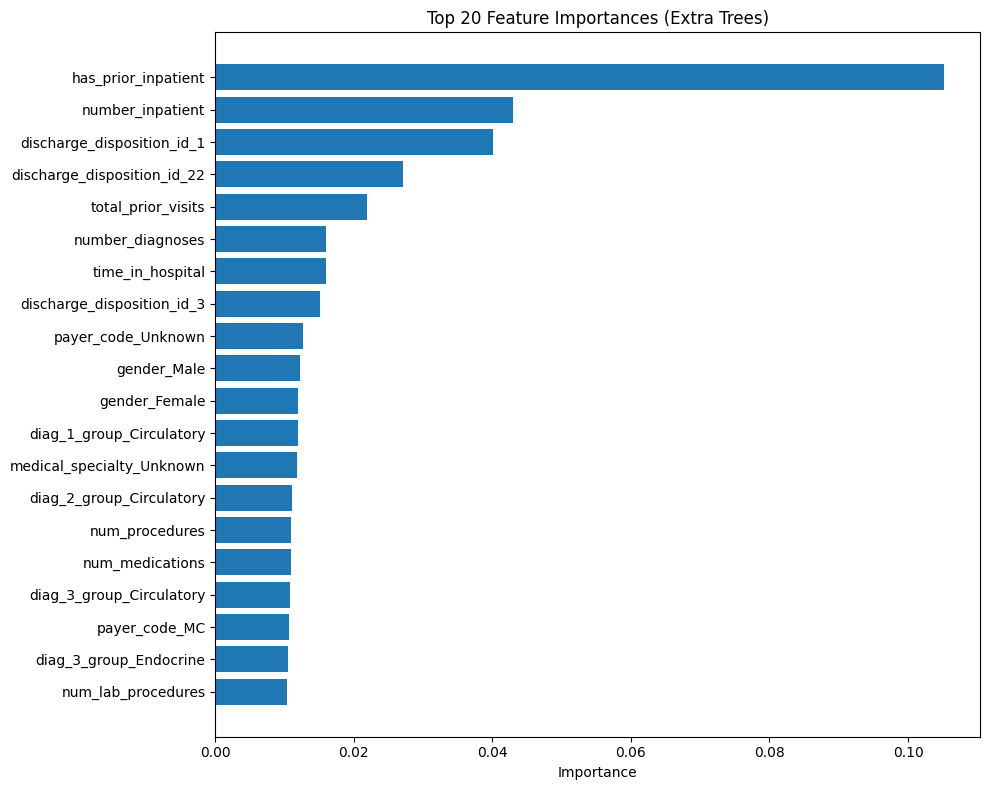

,Feature,Importance
0,has_prior_inpatient,0.105128
1,number_inpatient,0.042990
2,discharge_disposition_id_1,0.040069
3,discharge_disposition_id_22,0.027173
4,total_prior_visits,0.021943
5,number_diagnoses,0.016035
6,time_in_hospital,0.016012
7,discharge_disposition_id_3,0.015121
8,payer_code_Unknown,0.012655
9,gender_Male,0.012301


In [42]:
# ============================================
# STEP 38B - FEATURE IMPORTANCE (EXTRA TREES)
# ============================================

fitted_preprocessor = extra_trees_model.named_steps["preprocessor"]
fitted_et = extra_trees_model.named_steps["model"]

ohe = fitted_preprocessor.named_transformers_["cat"].named_steps["onehot"]
cat_feature_names = ohe.get_feature_names_out(categorical_features)
all_feature_names = numeric_features + list(cat_feature_names)

importances = fitted_et.feature_importances_

importance_df = (
    pd.DataFrame({
        "Feature":    all_feature_names,
        "Importance": importances
    })
    .sort_values("Importance", ascending=False)
    .head(20)
    .reset_index(drop=True)
)

plt.figure(figsize=(10, 8))
plt.barh(
    importance_df["Feature"][::-1],
    importance_df["Importance"][::-1]
)
plt.xlabel("Importance")
plt.title("Top 20 Feature Importances (Extra Trees)")
plt.tight_layout()
plt.show()

display(importance_df)

**Interpretation.** The strongest predictors were whether the patient had a prior inpatient visit (`has_prior_inpatient`), the number of prior inpatient visits and the discharge disposition (home, rehabilitation, skilled nursing). Length of stay, number of diagnoses and prior-visit totals followed. This matches the EDA, where the early-readmission rate rose from 8.6% with no prior inpatient visits to 31.4% with four or more.

Gender appears in the top 15 even though the EDA showed almost no difference (11.46% vs 11.30%). Impurity-based importance tends to favour binary features, so this ranking should not be read as evidence that gender matters.

# Model Selection Decision Log

The models considered were:

1. Dummy Classifier — baseline
2. Logistic Regression
3. Decision Tree
4. Random Forest
5. Extra Trees

Model selection is not based on accuracy alone because the early-readmission class is smaller.

The primary comparison metrics are:

- Recall
- Precision
- F1-score
- ROC-AUC
- Cross-validation performance

The final model was selected after considering both group-aware cross-validation performance and final held-out test performance.

Extra Trees had the highest PR-AUC in both group-aware cross-validation (0.214) and on the held-out test set (0.230), and the highest F1 at the chosen threshold. Random Forest had a marginally higher CV ROC-AUC (0.666 vs 0.663) and performed almost identically on the test set, so the models are close in ranking quality. Extra Trees was chosen because PR-AUC is the more informative metric for an imbalanced target, and it also gave a better precision/recall balance at the selected threshold.

In [43]:
# ============================================
# STEP 40 - SAVE RESULTS
# ============================================

results_df.to_csv(
    "/content/final_model_comparison.csv",
    index=False
)

cv_results_df.to_csv(
    "/content/cross_validation_results.csv",
    index=False
)

data_dictionary.to_csv(
    "/content/data_dictionary.csv",
    index=False
)

print("Result files saved successfully.")

Result files saved successfully.


In [44]:
# ============================================
# STEP 41 - DATASET FINGERPRINT
# ============================================

sha256_hash = hashlib.sha256()

with open(
    DATA_PATH,
    "rb"
) as f:

    for chunk in iter(
        lambda: f.read(1024 * 1024),
        b""
    ):

        sha256_hash.update(chunk)

dataset_hash = sha256_hash.hexdigest()

print("Dataset file:", DATA_PATH)
print("SHA-256 fingerprint:")
print(dataset_hash)

Dataset file: /content/diabetic_data.csv
SHA-256 fingerprint:
0689e7ec031237dc63031b938805c48377748761a3b26acab621567afa24df97


# Limitations

The analysis has several limitations:

1. The dataset contains historical hospital encounters from 130 US hospitals covering 1999–2008, so the patterns may not represent current healthcare settings.

2. The dataset contains repeated encounters for some patients. A patient-level split was therefore used to reduce information leakage between training and testing.

3. The target is based on the recorded `readmitted` outcome and does not represent all possible clinical reasons for readmission.

4. Class imbalance makes accuracy potentially misleading. Therefore, precision, recall, F1-score and ROC-AUC are considered.

5. Precision at the chosen operating point is modest (~0.21), meaning many positive predictions are false alarms. Class weighting was used deliberately to raise recall on the minority class; a higher-precision / lower-recall operating point is available by raising the threshold if that trade-off is preferred in practice.

6. Observed relationships in the data should not be interpreted as causal relationships.

7. The model should be considered a decision-support tool rather than a replacement for clinical judgement.

8. The dataset contains sensitive healthcare-related information, so responsible data handling and privacy considerations are important.

# Final Recommendation

Based on the group-aware cross-validation results and the final held-out test results, the selected model is Extra Trees.

Extra Trees had the highest PR-AUC in both group-aware cross-validation (0.214) and on the held-out test set (0.230), and the highest F1 at the chosen threshold. Random Forest had a marginally higher CV ROC-AUC (0.666 vs 0.663) and performed almost identically on the test set, so the models are close in ranking quality. Extra Trees was chosen because PR-AUC is the more informative metric for an imbalanced target, and it also gave a better precision/recall balance at the selected threshold.

On the held-out test set, Extra Trees achieved ROC-AUC 0.678 and PR-AUC 0.230, about twice the 11.3% base rate. At the selected threshold of 0.50 it identified 46% of early readmissions (recall) with 21% precision. This means the model ranks patients by relative risk better than it predicts individual outcomes, so it is best used to prioritise discharge planning or follow-up for the highest-risk patients, not to make decisions about individuals.

The threshold can be adjusted to the hospital's capacity. Lowering it to 0.40 raises recall to about 0.71 in cross-validation but cuts precision to about 0.16, meaning more false alarms. The strongest predictors were prior inpatient visits, discharge disposition, length of stay and number of diagnoses. These are associations, not causes, and the model should not replace clinical judgement.

# AI Use Declaration

Generative AI tools were used during the development of this project to support learning, coding assistance, debugging, explanation of machine-learning concepts, and improvement of documentation.

The group reviewed, tested and adapted the generated suggestions rather than treating AI output as automatically correct.

The final analysis, preprocessing decisions, model evaluation, interpretation and conclusions were reviewed by the group.

# Conclusion

This project investigated whether historical hospital encounter information could be used to classify early readmission risk.

The analysis followed a complete machine-learning workflow including data understanding, data-quality assessment, exploratory analysis, target construction, leakage review, patient-level splitting, preprocessing, baseline modelling, multiple machine-learning models, cross-validation and final evaluation.

Because early readmission represents a smaller class, model performance was assessed using multiple metrics rather than accuracy alone.

The final Extra Trees model provides a potential decision-support approach for prioritising encounters for additional planning or follow-up consideration. ROC-AUC of approximately 0.68 indicates modest but useful ranking ability.